# Experiment 5: K-Nearest Neighbours (K-NN)
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Write a program for the implementation of **K-Nearest Neighbours (K-NN)** in Python.

## Algorithm
1. Choose `k`.
2. For a query point compute the Euclidean distance to every training point.
3. Take the `k` closest points and predict the **majority class**.

K-NN is first implemented from scratch on the *handwritten digits* data set, then compared with scikit-learn.

Data shape: (1797, 64) | classes: [0 1 2 3 4 5 6 7 8 9]


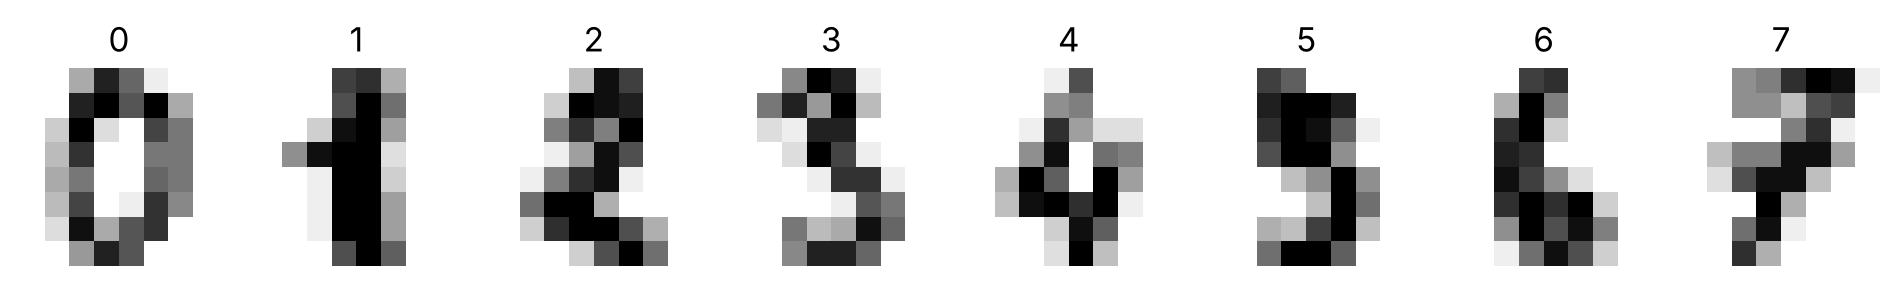

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

digits = load_digits()
X, y = digits.data, digits.target
print('Data shape:', X.shape, '| classes:', np.unique(y))

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img, lab in zip(axes, digits.images[:8], y[:8]):
    ax.imshow(img, cmap='gray_r'); ax.set_title(lab); ax.axis('off')
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [2]:
def knn_predict(X_train, y_train, X_test, k=3):
    # Euclidean distance between every test and every training point
    dist = np.sqrt(((X_test[:, None, :] - X_train[None, :, :]) ** 2).sum(axis=2))
    nearest = np.argsort(dist, axis=1)[:, :k]                  # indices of k nearest
    votes = y_train[nearest]
    return np.array([np.bincount(v).argmax() for v in votes])  # majority vote

pred_scratch = knn_predict(X_train, y_train, X_test, k=3)
print('From-scratch K-NN (k=3) accuracy:', round(accuracy_score(y_test, pred_scratch), 4))

sk = KNeighborsClassifier(n_neighbors=3).fit(X_train, y_train)
pred_sk = sk.predict(X_test)
print('scikit-learn  K-NN (k=3) accuracy:', round(accuracy_score(y_test, pred_sk), 4))
print('Predictions agree on', round((pred_scratch == pred_sk).mean() * 100, 2), '% of test samples')

From-scratch K-NN (k=3) accuracy: 0.9861
scikit-learn  K-NN (k=3) accuracy: 0.9861
Predictions agree on 100.0 % of test samples


Best k = 1 with accuracy 0.9861


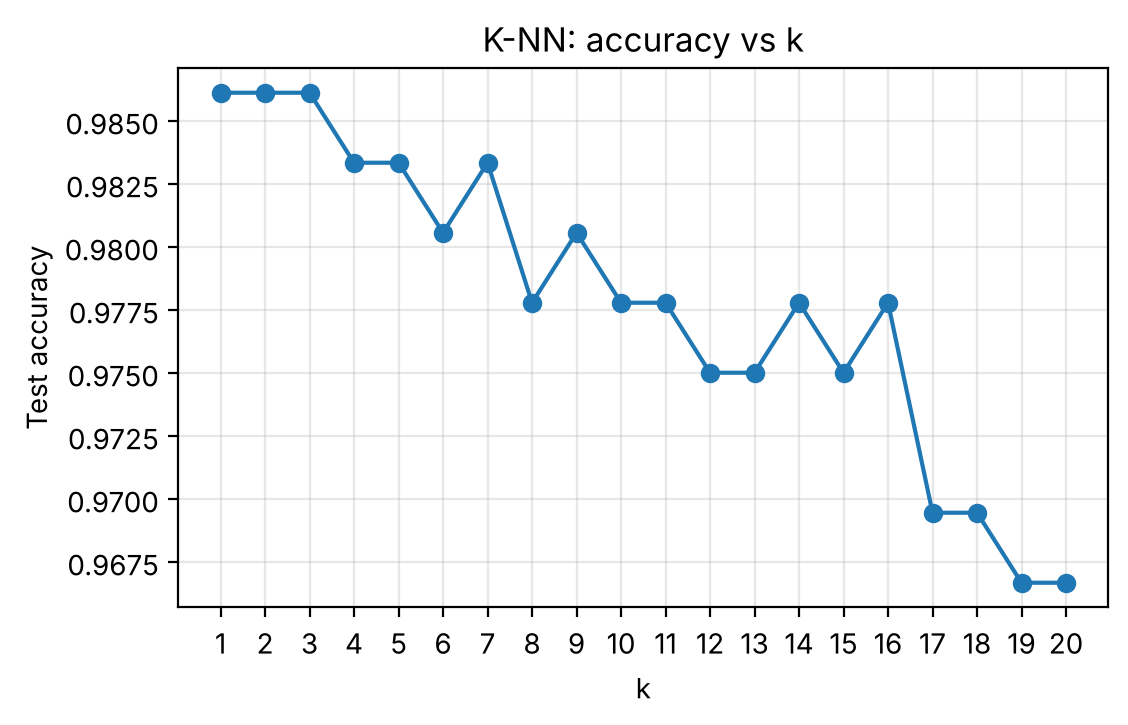

In [3]:
# Effect of k on accuracy
ks = range(1, 21)
accs = [accuracy_score(y_test, knn_predict(X_train, y_train, X_test, k)) for k in ks]
best_k = ks[int(np.argmax(accs))]
print('Best k =', best_k, 'with accuracy', round(max(accs), 4))

plt.figure(figsize=(6, 3.5))
plt.plot(list(ks), accs, marker='o')
plt.xlabel('k'); plt.ylabel('Test accuracy'); plt.title('K-NN: accuracy vs k')
plt.xticks(list(ks)); plt.grid(alpha=0.3); plt.show()

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      1.00      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       1.00      1.00      1.00        36
           8       0.97      0.91      0.94        35
           9       1.00      0.94      0.97        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



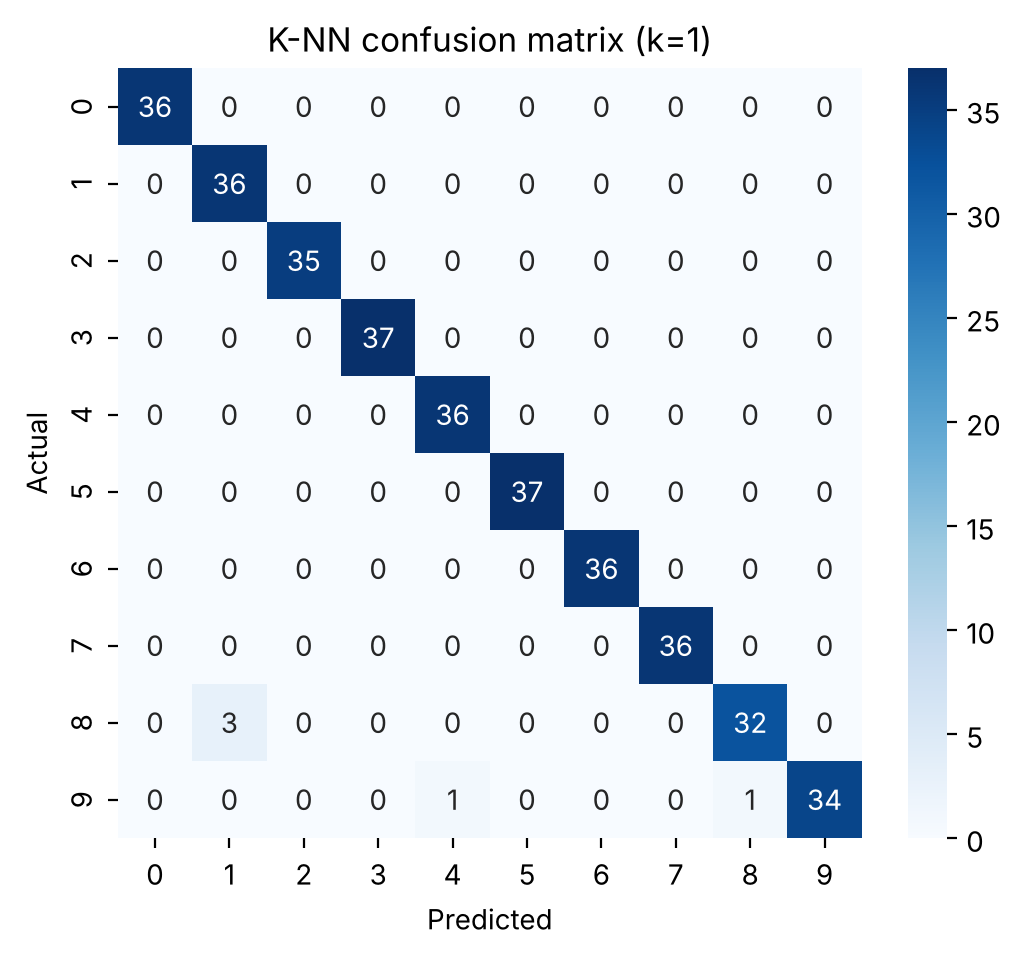

In [4]:
final_pred = knn_predict(X_train, y_train, X_test, k=best_k)
print(classification_report(y_test, final_pred))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, final_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'K-NN confusion matrix (k={best_k})')
plt.show()

## Result
The from-scratch K-NN matches scikit-learn's implementation and reaches about 98-99 % accuracy on handwritten digits. Accuracy depends on `k`, which was chosen with the accuracy-vs-k plot.